# 03. Phân tích khám phá dữ liệu

EDA giúp nhóm hiểu phân phối dữ liệu train và xem các đặc điểm hồ sơ có liên hệ thế nào với `TARGET`. Kết quả định hướng bước chuẩn bị dữ liệu và tạo đặc trưng; các biểu đồ không chứng minh quan hệ nhân quả hay chất lượng dự báo ngoài mẫu.

Notebook chỉ phân tích 184.506 hồ sơ train. Các bảng bureau và POS được đọc từ đầu ra của notebook 02 để dùng cùng phạm vi và cách tổng hợp.


## Mục lục

- [01. Đọc dữ liệu train](#part-1)
- [02. Phân tích khám phá với TARGET (EDA)](#part-2)
  - [02.1. Biến số với TARGET](#muc-06-1)
  - [02.2. Biến phân loại với TARGET](#muc-06-2)
  - [02.3. Tương quan giữa các biến](#muc-06-3)
  - [02.4. Tuổi và thâm niên làm việc](#muc-06-4)
  - [02.5. Lịch sử tín dụng ở cấp hồ sơ](#muc-06-5)
  - [02.6. Phân phối các biến tài chính](#eda-financial-distribution)
  - [02.7. Tỷ số khoản vay và khoản trả trên thu nhập](#eda-financial-ratios)
- [03. Phạm vi lịch sử dùng trong phân tích](#part-3)
- [04. Kết luận EDA](#part-4)


<a id="part-1"></a>

## 01. Đọc dữ liệu train

Phần này nạp đúng tập train đã xác định ở notebook 01 cùng nhãn `TARGET`. Không tạo lại tập chia và không dùng nhãn validation hoặc test.


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
plt.rcParams['figure.figsize'] = (9, 4)

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from connectors.Connector import Connector
from models.HomeCreditQuality import HomeCreditQuality


No event loop hook running.


In [2]:
connector = Connector()
connector.connect()
try:
    quality = HomeCreditQuality(connector)
    train = quality.loadTrain()
finally:
    connector.disConnect()

EDA_DATA = ROOT / 'data/eda'
history_results = {
    'bureau_by_app': pd.read_parquet(EDA_DATA / 'bureau_by_application.parquet'),
    'pos_by_app': pd.read_parquet(EDA_DATA / 'pos_by_application.parquet'),
    'eda_scope': pd.read_csv(EDA_DATA / 'history_scope.csv')
}
print('Hồ sơ train:', len(train), '| Tỷ lệ TARGET = 1:', train['TARGET'].mean())

Hồ sơ train: 184506 | Tỷ lệ TARGET = 1: 0.08072908198107379


### Kết luận mục 01

Đã nạp **184.506 hồ sơ train**, trong đó tỷ lệ `TARGET = 1` là **8,073%**. Các phân tích tiếp theo dùng tập này cùng đầu ra bureau/POS từ notebook 02.


<a id="muc-06"></a>

<a id="part-2"></a>

## 02. Phân tích khám phá với TARGET (EDA)

Phần này mô tả phân phối và mối liên hệ giữa đặc điểm hồ sơ với `TARGET` trên train. Kết quả giúp nhóm nhận diện điểm cần lưu ý khi chuẩn bị dữ liệu và tạo đặc trưng. Các nhóm được so sánh theo số hồ sơ và tỷ lệ; EDA không được dùng để kết luận nguyên nhân hay chất lượng mô hình.

<a id="muc-06-1"></a>

### 02.1. Biến số với TARGET

Chia thu nhập, khoản vay, annuity và ba điểm `EXT_SOURCE` thành tối đa năm nhóm phân vị trên train. Bảng ghi số hồ sơ, số trường hợp `TARGET = 1` và tỷ lệ của từng nhóm; giá trị thiếu được giữ thành nhóm riêng. Q1 đến Q5 đi từ giá trị thấp đến cao. Nếu nhiều quan sát trùng ở ranh giới, quy mô nhóm có thể khác nhau.


**Tính tỷ lệ TARGET theo nhóm ngũ phân vị**

In [3]:
numeric_eda_columns = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
                       'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
numeric_target_rows = []
for column in numeric_eda_columns:
    groups = pd.qcut(train[column], q=5, duplicates='drop')
    grouped = train.groupby(groups, observed=True)['TARGET'].agg(n='size', positive_n='sum')
    grouped['target_rate_pct'] = grouped['positive_n'] / grouped['n'] * 100
    grouped.index = grouped.index.astype(str)
    missing_target = train.loc[train[column].isna(), 'TARGET']
    if len(missing_target):
        grouped.loc['Missing'] = [len(missing_target), missing_target.sum(), missing_target.mean() * 100]
    grouped[['n', 'positive_n']] = grouped[['n', 'positive_n']].astype('int64')
    grouped['column'] = column
    numeric_target_rows.append(grouped.rename_axis('group').reset_index())
numeric_target = pd.concat(numeric_target_rows, ignore_index=True)
display(numeric_target)


,group,n,positive_n,target_rate_pct,column
0,"(25649.999, 99000.0]",38166,3179,8.329403,AMT_INCOME_TOTAL
1,"(99000.0, 135000.0]",51382,4402,8.567203,AMT_INCOME_TOTAL
2,"(135000.0, 162000.0]",21490,1868,8.692415,AMT_INCOME_TOTAL
3,"(162000.0, 225000.0]",45251,3653,8.072750,AMT_INCOME_TOTAL
4,"(225000.0, 18000090.0]",28217,1793,6.354325,AMT_INCOME_TOTAL
...,...,...,...,...,...
29,"(0.331, 0.476]",29507,2620,8.879249,EXT_SOURCE_3
30,"(0.476, 0.592]",29887,1700,5.688092,EXT_SOURCE_3
31,"(0.592, 0.694]",29720,1331,4.478466,EXT_SOURCE_3
32,"(0.694, 0.896]",28900,965,3.339100,EXT_SOURCE_3


**Vẽ tỷ lệ TARGET theo nhóm của từng biến số**

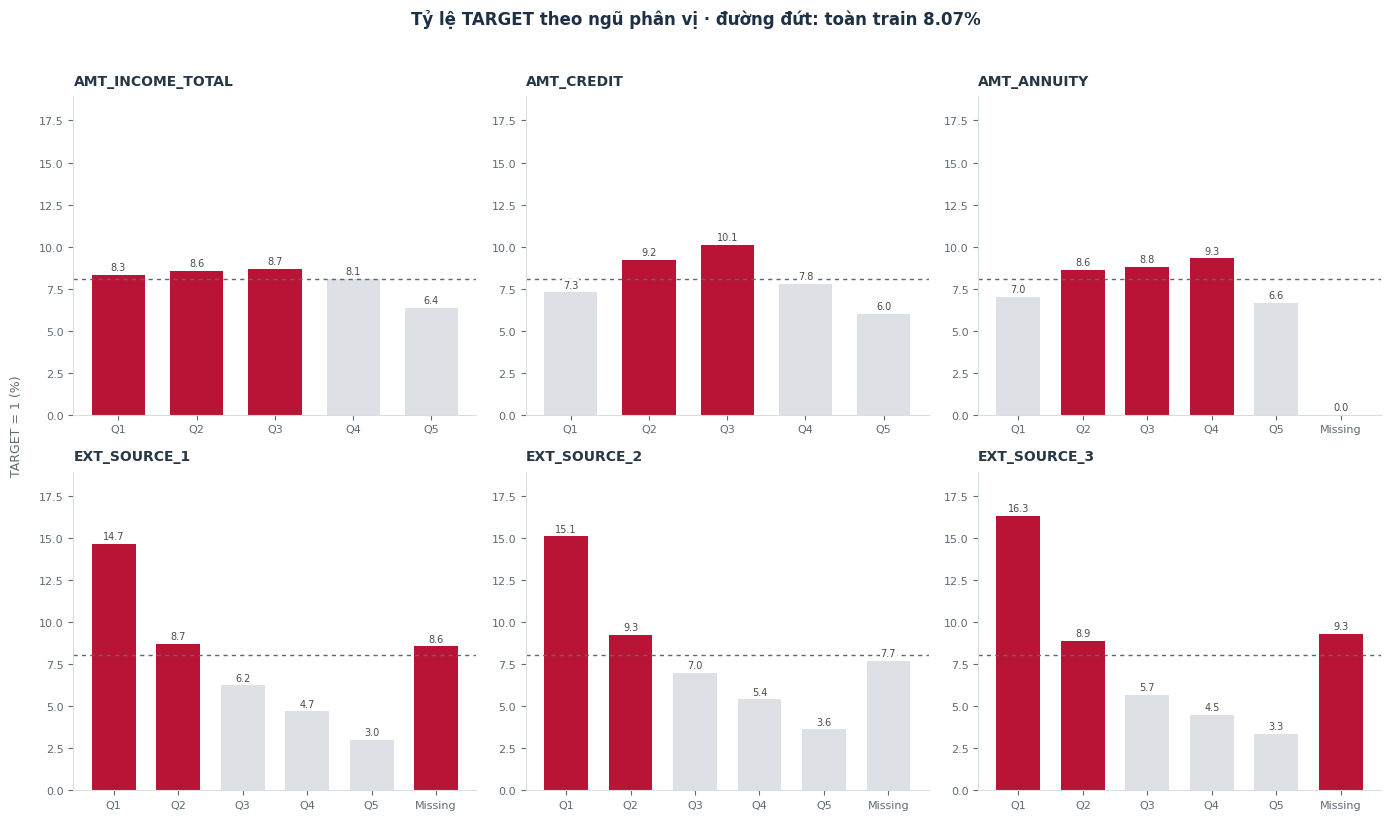

In [4]:
default_rate = train['TARGET'].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(14, 8), facecolor='white')
axis_max = numeric_target['target_rate_pct'].max() * 1.16
for column, ax in zip(numeric_eda_columns, axes.flat):
    is_column = numeric_target['column'] == column
    grouped = numeric_target.loc[is_column].set_index('group')
    rates = grouped['target_rate_pct'].to_numpy()
    labels = ['Missing' if group == 'Missing' else f'Q{i + 1}'
              for i, group in enumerate(grouped.index)]
    colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
    bars = ax.bar(range(len(rates)), rates, color=colors, width=.68)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=7, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
    ax.axhline(default_rate, color='#596875', linestyle=(0, (3, 3)), linewidth=1, zorder=1)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_ylim(0, axis_max)
    ax.set_title(column, loc='left', fontsize=10, fontweight='semibold', color='#263746', pad=8)
    ax.set_ylabel('')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
    ax.tick_params(colors='#5E6B75', labelsize=8)
fig.supylabel('TARGET = 1 (%)', x=.01, fontsize=9, color='#5E6B75')
fig.suptitle(f'T\u1ef7 l\u1ec7 TARGET theo ng\u0169 ph\u00e2n v\u1ecb \u00b7 \u0111\u01b0\u1eddng \u0111\u1ee9t: to\u00e0n train {default_rate:.2f}%',
             fontsize=12, fontweight='semibold', color='#1D3045', y=1.02)
fig.tight_layout()
plt.show()


Tỷ lệ `TARGET = 1` nhìn chung thấp hơn ở các nhóm có điểm `EXT_SOURCE` cao. Quan hệ của thu nhập, khoản vay và annuity không nhất thiết tăng hoặc giảm đều theo phân vị. Đây là mô tả trong train; các biểu đồ chưa đo khả năng dự báo trên dữ liệu mới và không cho biết nguyên nhân.

<a id="muc-06-2"></a>

### 02.2. Biến phân loại với TARGET

So sánh số hồ sơ và tỷ lệ `TARGET = 1` theo loại thu nhập, học vấn và loại hợp đồng. Biểu đồ chỉ hiển thị nhóm có ít nhất 100 hồ sơ. Đây là ngưỡng mô tả để hạn chế diễn giải các tỷ lệ dựa trên nhóm rất nhỏ, không phải quy tắc loại dữ liệu.

**Tính tỷ lệ TARGET theo nhóm phân loại**

In [5]:
categorical_target_rows = []
categorical_columns = ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_CONTRACT_TYPE']
for column in categorical_columns:
    grouped = train.groupby(column, dropna=False)['TARGET'].agg(n='size', positive_n='sum')
    grouped['target_rate_pct'] = grouped['positive_n'] / grouped['n'] * 100
    grouped['small_group_under_100'] = (grouped['n'] < 100)
    grouped['column'] = column
    categorical_target_rows.append(grouped.rename_axis('group').reset_index())
categorical_target = pd.concat(categorical_target_rows, ignore_index=True)
display(categorical_target)


,group,n,positive_n,target_rate_pct,small_group_under_100,column
0,Businessman,6,0,0.000000,True,NAME_INCOME_TYPE
1,Commercial associate,42924,3258,7.590159,False,NAME_INCOME_TYPE
2,Maternity leave,2,0,0.000000,True,NAME_INCOME_TYPE
3,Pensioner,33116,1790,5.405242,False,NAME_INCOME_TYPE
4,State servant,13158,753,5.722754,False,NAME_INCOME_TYPE
5,Student,7,0,0.000000,True,NAME_INCOME_TYPE
6,Unemployed,11,2,18.181818,True,NAME_INCOME_TYPE
7,Working,95282,9092,9.542201,False,NAME_INCOME_TYPE
8,Academic degree,90,2,2.222222,True,NAME_EDUCATION_TYPE
9,Higher education,44914,2418,5.383622,False,NAME_EDUCATION_TYPE


**Vẽ tỷ lệ TARGET ở các nhóm có ít nhất 100 hồ sơ**

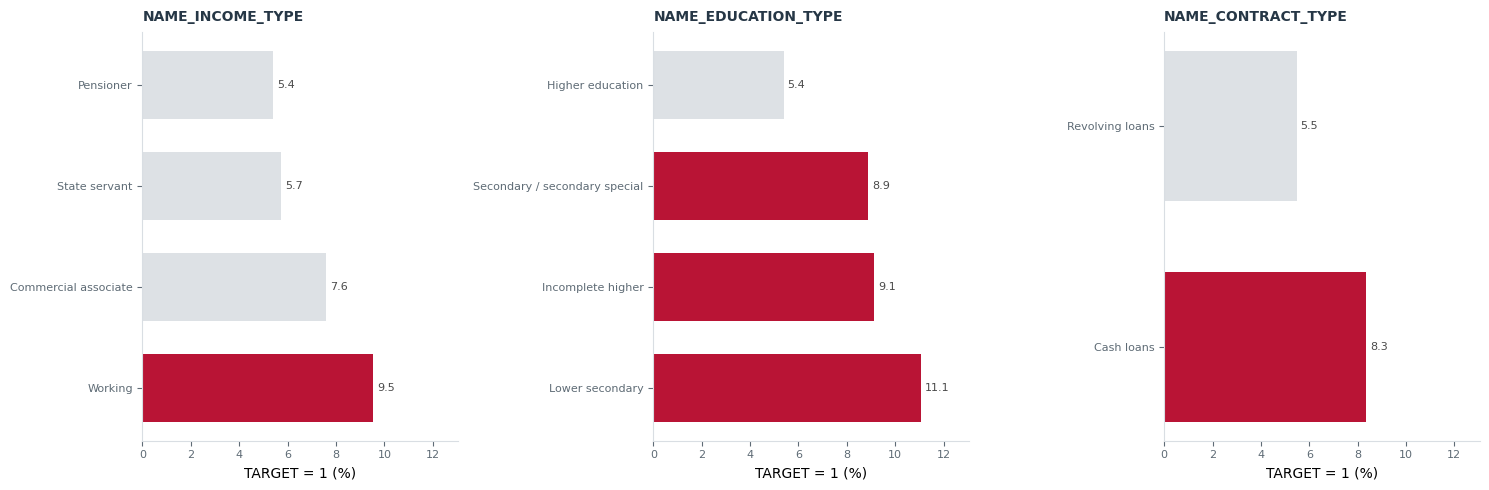

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor='white')
visible_categories = categorical_target.loc[categorical_target['n'] >= 100]
axis_max = visible_categories['target_rate_pct'].max() * 1.18
for column, ax in zip(categorical_columns, axes):
    is_column = visible_categories['column'] == column
    grouped = visible_categories.loc[is_column].set_index('group')
    rates = grouped['target_rate_pct'].sort_values(ascending=False)
    colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
    bars = ax.barh(rates.index.astype(str), rates.to_numpy(), color=colors, height=.68)
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
    ax.set_xlim(0, axis_max)
    ax.set_title(column, loc='left', fontsize=10, fontweight='semibold', color='#263746', pad=8)
    ax.set_xlabel('TARGET = 1 (%)')
    ax.set_ylabel('')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
    ax.tick_params(colors='#5E6B75', labelsize=8)
fig.tight_layout()
plt.show()


Trong các nhóm được xem, tỷ lệ `TARGET = 1` là **9,54%** ở Working (**95.282 hồ sơ**) và **5,41%** ở Pensioner (**33.116 hồ sơ**). Tỷ lệ ở nhóm Secondary là **8,90%** (**131.010 hồ sơ**), so với **5,38%** ở Higher education (**44.914 hồ sơ**). Cash loans có tỷ lệ **8,35%**, còn Revolving loans là **5,47%**.

Đây là khác biệt giữa các nhóm trong train. Cơ cấu khách hàng và khoản vay có thể khác nhau; các tỷ lệ này không cho biết nghề nghiệp hay học vấn gây ra rủi ro.

<a id="muc-06-3"></a>

### 02.3. Tương quan giữa các biến

Tính tương quan Spearman giữa một số biến số được chọn, gồm cả `TARGET`; loại mã hồ sơ khỏi phép tính. Bảng ghi số cặp có đủ dữ liệu cho mỗi phép so sánh. Mỗi cặp chỉ dùng các dòng không thiếu ở cả hai biến; không điền giá trị khuyết để tính tương quan.

**Tính Spearman và số cặp đủ dữ liệu**

In [7]:
corr_columns = numeric_eda_columns + ['AMT_GOODS_PRICE', 'DAYS_BIRTH', 'TARGET']
correlation = train[corr_columns].corr(method='spearman')
observed_pairs = train[corr_columns].notna().astype('int64')
pair_counts = observed_pairs.T.dot(observed_pairs)
target_correlation = correlation['TARGET'].drop('TARGET').to_frame('spearman_target')
target_correlation['valid_pair_n'] = pair_counts.loc[target_correlation.index, 'TARGET']
display(target_correlation.sort_values('spearman_target'))
display(correlation)


,spearman_target,valid_pair_n
EXT_SOURCE_3,-0.167997,147908
EXT_SOURCE_1,-0.152656,80648
EXT_SOURCE_2,-0.145809,184115
AMT_GOODS_PRICE,-0.033038,184352
AMT_INCOME_TOTAL,-0.020223,184506
AMT_CREDIT,-0.019610,184506
AMT_ANNUITY,-0.001596,184498
DAYS_BIRTH,0.079716,184506


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AMT_GOODS_PRICE,DAYS_BIRTH,TARGET
AMT_INCOME_TOTAL,1.000000,0.411984,0.481120,0.079894,0.178547,-0.087351,0.416089,0.081799,-0.020223
AMT_CREDIT,0.411984,1.000000,0.830575,0.165800,0.129287,0.028830,0.984940,-0.069456,-0.019610
AMT_ANNUITY,0.481120,0.830575,1.000000,0.112181,0.127243,0.018504,0.828553,0.004320,-0.001596
EXT_SOURCE_1,0.079894,0.165800,0.112181,1.000000,0.219476,0.184571,0.177373,-0.600050,-0.152656
EXT_SOURCE_2,0.178547,0.129287,0.127243,0.219476,1.000000,0.105279,0.139463,-0.105606,-0.145809
EXT_SOURCE_3,-0.087351,0.028830,0.018504,0.184571,0.105279,1.000000,0.035573,-0.207052,-0.167997
AMT_GOODS_PRICE,0.416089,0.984940,0.828553,0.177373,0.139463,0.035573,1.000000,-0.071782,-0.033038
DAYS_BIRTH,0.081799,-0.069456,0.004320,-0.600050,-0.105606,-0.207052,-0.071782,1.000000,0.079716
TARGET,-0.020223,-0.019610,-0.001596,-0.152656,-0.145809,-0.167997,-0.033038,0.079716,1.000000


**Ma trận tương quan của các biến được chọn**

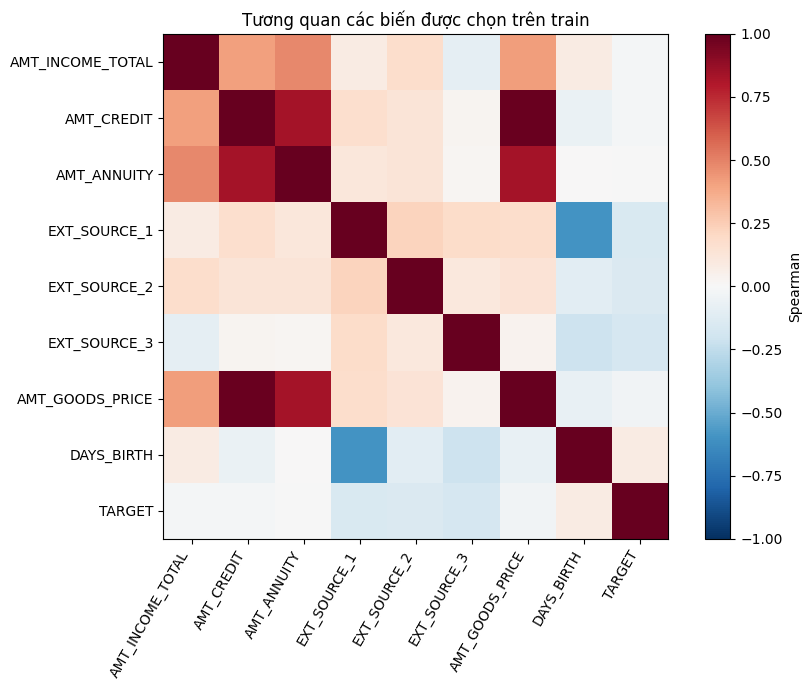

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(corr_columns)), corr_columns, rotation=60, ha='right')
ax.set_yticks(range(len(corr_columns)), corr_columns)
fig.colorbar(image, ax=ax, label='Spearman')
ax.set_title('Tương quan các biến được chọn trên train')
plt.tight_layout()
plt.show()


Tương quan Spearman giữa `TARGET` với `EXT_SOURCE_1`, `EXT_SOURCE_2` và `EXT_SOURCE_3` lần lượt khoảng **−0,153**, **−0,146** và **−0,168**. Các tương quan đơn biến của thu nhập, khoản vay và annuity thấp hơn. Tương quan thấp không đủ căn cứ để loại biến: quan hệ có thể phi tuyến hoặc phụ thuộc vào đặc trưng khác. Những biến có thông tin tương đồng sẽ được xem xét cùng kết quả mô hình ở bước sau.

<a id="muc-06-4"></a>

### 02.4. Tuổi và thâm niên làm việc

Đổi `DAYS_BIRTH` và `DAYS_EMPLOYED` sang số năm để mô tả phân phối, rồi so sánh tỷ lệ `TARGET = 1` theo nhóm phân vị. Giá trị sentinel `DAYS_EMPLOYED = 365243` được giữ riêng, không diễn giải thành thời gian làm việc.

EDA kiểm tra mối liên hệ của thu nhập và sự ổn định việc làm với TARGET trên dữ liệu dự án thay vì giả định trước kết quả.

**Đổi ngày thành tuổi và thâm niên để mô tả**

In [9]:
age_work_view = pd.DataFrame(index=train.index)
age_work_view['AGE_YEARS'] = -train['DAYS_BIRTH'] / 365.25
age_work_view['EMPLOYMENT_YEARS'] = -train['DAYS_EMPLOYED'].where(
    (train['DAYS_EMPLOYED'] <= 0)
) / 365.25
age_work_profile = age_work_view.describe(percentiles=[.25, .5, .75]).T
display(age_work_profile)


,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,184506.0,43.886910,11.954179,20.503765,33.941136,43.104723,53.874743,69.073238
EMPLOYMENT_YEARS,151384.0,6.548435,6.433375,-0.000000,2.108145,4.517454,8.700890,49.040383


**Vẽ phân phối tuổi và thâm niên**

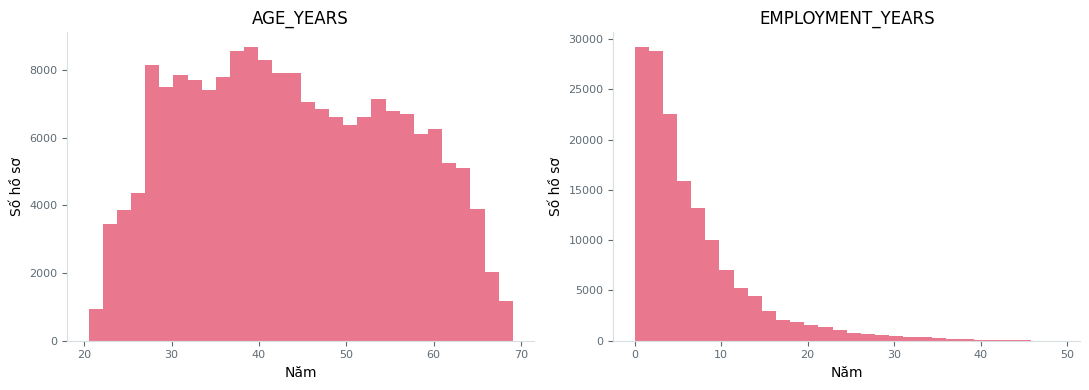

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for column, ax in zip(age_work_view, axes):
    age_work_view[column].dropna().hist(bins=30, ax=ax, color='#E9788F')
    ax.set_xlabel('Năm')
    ax.set_ylabel('Số hồ sơ')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
    ax.tick_params(colors='#5E6B75', labelsize=8)
    ax.set_title(column)
plt.tight_layout()
plt.show()


**Tính tỷ lệ TARGET theo tuổi và thâm niên**

In [11]:
age_work_target_rows = []
for column in age_work_view:
    groups = pd.qcut(age_work_view[column], q=5, duplicates='drop')
    grouped = train.groupby(groups, observed=True)['TARGET'].agg(n='size', positive_n='sum')
    grouped['target_rate_pct'] = grouped['positive_n'] / grouped['n'] * 100
    grouped.index = grouped.index.astype(str)
    if column == 'EMPLOYMENT_YEARS':
        sentinel_target = train.loc[(train['DAYS_EMPLOYED'] == 365243), 'TARGET']
        if len(sentinel_target):
            grouped.loc['Sentinel 365243'] = [len(sentinel_target), sentinel_target.sum(),
                                               sentinel_target.mean() * 100]
    other_missing = age_work_view[column].isna()
    if column == 'EMPLOYMENT_YEARS':
        other_missing &= (train['DAYS_EMPLOYED'] != 365243)
    if other_missing.any():
        missing_target = train.loc[other_missing, 'TARGET']
        grouped.loc['Thiếu / chưa xác minh'] = [len(missing_target), missing_target.sum(),
                                                missing_target.mean() * 100]
    grouped[['n', 'positive_n']] = grouped[['n', 'positive_n']].astype('int64')
    grouped['column'] = column
    age_work_target_rows.append(grouped.rename_axis('group').reset_index())
age_work_target = pd.concat(age_work_target_rows, ignore_index=True)
display(age_work_target)


,group,n,positive_n,target_rate_pct,column
0,"(20.503, 31.981]",36908,4179,11.322748,AGE_YEARS
1,"(31.981, 39.439]",36897,3442,9.328672,AGE_YEARS
2,"(39.439, 47.151]",36904,2918,7.907002,AGE_YEARS
3,"(47.151, 56.036]",36897,2463,6.675339,AGE_YEARS
4,"(56.036, 69.073]",36900,1893,5.130081,AGE_YEARS
5,"(-0.001, 1.695]",30331,3412,11.249217,EMPLOYMENT_YEARS
6,"(1.695, 3.433]",30234,3215,10.633724,EMPLOYMENT_YEARS
7,"(3.433, 5.925]",30285,2704,8.928512,EMPLOYMENT_YEARS
8,"(5.925, 10.081]",30271,2228,7.360180,EMPLOYMENT_YEARS
9,"(10.081, 49.04]",30263,1544,5.101940,EMPLOYMENT_YEARS


**Vẽ nhóm tuổi, thâm niên và sentinel riêng**

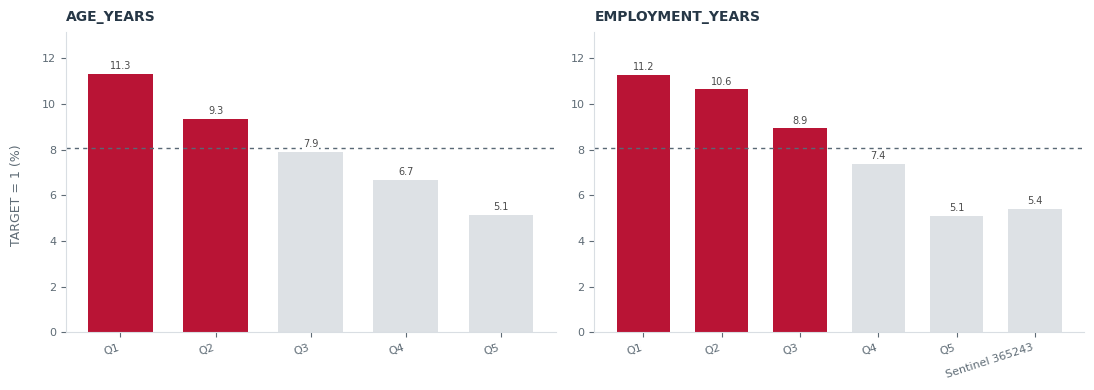

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor='white')
axis_max = age_work_target['target_rate_pct'].max() * 1.16
for column, ax in zip(age_work_view, axes):
    is_column = age_work_target['column'] == column
    grouped = age_work_target.loc[is_column].set_index('group')
    labels = [f'Q{i + 1}' if str(group).startswith('(') else str(group)
              for i, group in enumerate(grouped.index)]
    rates = grouped['target_rate_pct'].to_numpy()
    colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
    bars = ax.bar(range(len(rates)), rates, color=colors, width=.68)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=7, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
    ax.set_xticks(range(len(labels)), labels, rotation=18, ha='right')
    ax.set_ylim(0, axis_max)
    ax.axhline(default_rate, color='#596875', linestyle=(0, (3, 3)), linewidth=1, zorder=1)
    ax.set_title(column, loc='left', fontsize=10, fontweight='semibold', color='#263746', pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
    ax.tick_params(colors='#5E6B75', labelsize=8)
fig.supylabel('TARGET = 1 (%)', x=.01, fontsize=9, color='#5E6B75')
fig.tight_layout()
plt.show()


Tuổi trong train nằm trong khoảng **20,50–69,07 năm**, trung vị **43,10 năm**. Tỷ lệ `TARGET = 1` giảm từ **11,32%** ở Q1 (**36.908 hồ sơ**) xuống **5,13%** ở Q5 (**36.900 hồ sơ**).

Có **151.384 hồ sơ** có thâm niên hợp lệ; trung vị là **4,52 năm**. Tỷ lệ `TARGET = 1` ở Q1 và Q5 lần lượt khoảng **11,25%** và **5,10%**. Nhóm **33.122 hồ sơ** mang sentinel có tỷ lệ **5,41%** và được báo cáo riêng. Các khác biệt này có thể đi cùng cơ cấu khách hàng khác nhau; chúng không chứng minh quan hệ nhân quả hay hiệu năng dự báo ngoài mẫu.

<a id="muc-06-5"></a>

### 02.5. Lịch sử tín dụng ở cấp hồ sơ

Tổng hợp một số dấu hiệu bureau và POS thành một dòng cho mỗi `SK_ID_CURR`, sau đó so sánh tỷ lệ `TARGET = 1` giữa các nhóm. Phân tích giữ đủ hồ sơ train và phân biệt hồ sơ không có lịch sử với hồ sơ có dữ liệu nhưng chưa xác minh được dấu hiệu.

Ở bureau, dấu hiệu là khoản có tiền quá hạn được báo cáo trong những dòng thỏa điều kiện thời gian nêu trong code. Ở POS, dấu hiệu là snapshot trước hồ sơ có `SK_DPD > 0`. Hai cách đo phản ánh thông tin khác nhau; không xem chúng là số kỳ vi phạm hay lịch sử trả nợ đầy đủ của khách hàng.

Notebook chỉ đọc các cột cần thiết. Quy tắc thời gian ở đây phục vụ EDA; quy tắc tạo đặc trưng cho mô hình được chốt ở notebook 04.

In [13]:
bureau_by_app = history_results['bureau_by_app']
bureau_application_view = train[['SK_ID_CURR', 'TARGET']].merge(
    bureau_by_app, on='SK_ID_CURR', how='left', validate='one_to_one'
)
bureau_group_order = ['Không có lịch sử bureau', 'Chưa ghi nhận tiền quá hạn',
                       'Có khoản báo tiền quá hạn', 'Còn thông tin chưa xác minh']
# Ưu tiên: không có lịch sử -> có tín hiệu -> chưa xác minh -> chưa ghi nhận.
no_history = bureau_application_view['source_rows'].isna()
has_overdue = bureau_application_view['overdue_rows'] > 0
unverified = bureau_application_view['usable_rows'] < bureau_application_view['source_rows']
bureau_application_view['history_group'] = bureau_group_order[1]
bureau_application_view.loc[unverified, 'history_group'] = bureau_group_order[3]
bureau_application_view.loc[has_overdue, 'history_group'] = bureau_group_order[2]
bureau_application_view.loc[no_history, 'history_group'] = bureau_group_order[0]
bureau_application_view['history_group'] = pd.Categorical(
    bureau_application_view['history_group'], categories=bureau_group_order
)
bureau_target = bureau_application_view.groupby('history_group', observed=False)['TARGET'].agg(
    n='size', positive_n='sum', target_rate='mean'
)
bureau_target['target_rate_pct'] = bureau_target.pop('target_rate') * 100
display(bureau_target)
bureau_scope = history_results['eda_scope'].set_index('source').loc['bureau']
print('Dòng bureau chưa đủ điều kiện quan sát:', int(bureau_scope['unverified_rows']))


Dòng bureau chưa đủ điều kiện quan sát: 80


,n,positive_n,target_rate_pct
history_group,,,
Không có lịch sử bureau,26341,2667,10.124900
Chưa ghi nhận tiền quá hạn,156055,11894,7.621672
Có khoản báo tiền quá hạn,2034,323,15.880039
Còn thông tin chưa xác minh,76,11,14.473684


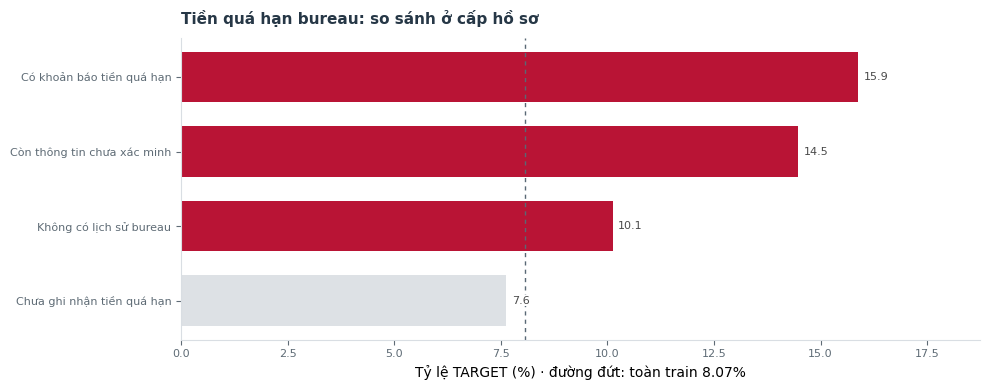

In [14]:
rates = bureau_target['target_rate_pct'].sort_values(ascending=False)
colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
fig, ax = plt.subplots(figsize=(10, 4), facecolor='white')
bars = ax.barh(rates.index.astype(str), rates.to_numpy(), color=colors, height=.68)
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.1f', padding=4, fontsize=8, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
ax.axvline(default_rate, color='#596875', linestyle=(0, (3, 3)), linewidth=1)
ax.set_xlabel(f'T\u1ef7 l\u1ec7 TARGET (%) \u00b7 \u0111\u01b0\u1eddng \u0111\u1ee9t: to\u00e0n train {default_rate:.2f}%')
ax.set_ylabel('')
ax.set_title('Ti\u1ec1n qu\u00e1 h\u1ea1n bureau: so s\u00e1nh \u1edf c\u1ea5p h\u1ed3 s\u01a1', loc='left', fontsize=11,
             fontweight='semibold', color='#263746', pad=10)
ax.set_xlim(0, max(rates.max(), default_rate) * 1.18)
ax.grid(False)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#D9DEE3')
ax.tick_params(colors='#5E6B75', labelsize=8)
fig.tight_layout()
plt.show()


In [15]:
pos_by_app = history_results['pos_by_app']
pos_application_view = train[['SK_ID_CURR', 'TARGET']].merge(
    pos_by_app, on='SK_ID_CURR', how='left', validate='one_to_one'
)
pos_group_order = ['Không có lịch sử POS', 'Chưa ghi nhận DPD > 0',
                    'Có snapshot DPD > 0', 'Còn thông tin chưa xác minh']
no_history = pos_application_view['source_rows'].isna()
has_dpd = pos_application_view['positive_dpd_rows'] > 0
unverified = pos_application_view['usable_rows'] < pos_application_view['source_rows']
pos_application_view['history_group'] = pos_group_order[1]
pos_application_view.loc[unverified, 'history_group'] = pos_group_order[3]
pos_application_view.loc[has_dpd, 'history_group'] = pos_group_order[2]
pos_application_view.loc[no_history, 'history_group'] = pos_group_order[0]
pos_application_view['history_group'] = pd.Categorical(
    pos_application_view['history_group'], categories=pos_group_order
)
pos_target = pos_application_view.groupby('history_group', observed=False)['TARGET'].agg(
    n='size', positive_n='sum', target_rate='mean'
)
pos_target['target_rate_pct'] = pos_target.pop('target_rate') * 100
display(pos_target)


,n,positive_n,target_rate_pct
history_group,,,
Không có lịch sử POS,10834,755,6.968802
Chưa ghi nhận DPD > 0,140842,10811,7.675977
Có snapshot DPD > 0,32830,3329,10.140116
Còn thông tin chưa xác minh,0,0,NaN


**Vẽ tỷ lệ TARGET theo lịch sử POS**

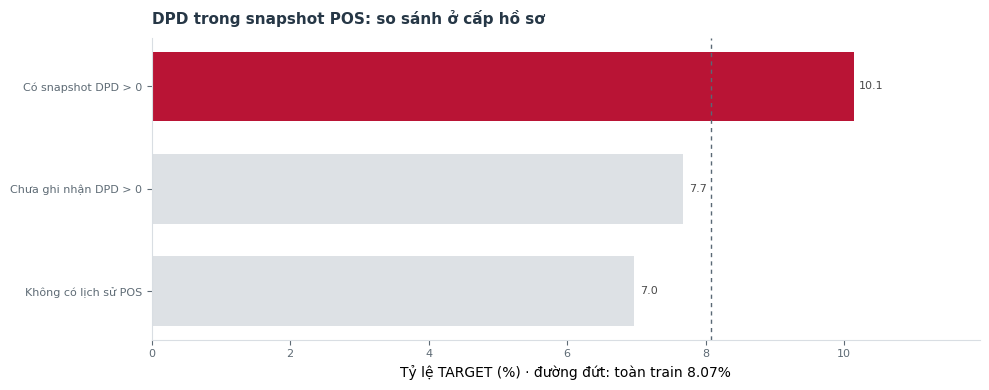

In [16]:
rates = pos_target['target_rate_pct'].dropna().sort_values(ascending=False)
colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
fig, ax = plt.subplots(figsize=(10, 4), facecolor='white')
bars = ax.barh(rates.index.astype(str), rates.to_numpy(), color=colors, height=.68)
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.1f', padding=4, fontsize=8, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
ax.axvline(default_rate, color='#596875', linestyle=(0, (3, 3)), linewidth=1)
ax.set_xlabel(f'T\u1ef7 l\u1ec7 TARGET (%) \u00b7 \u0111\u01b0\u1eddng \u0111\u1ee9t: to\u00e0n train {default_rate:.2f}%')
ax.set_ylabel('')
ax.set_title('DPD trong snapshot POS: so s\u00e1nh \u1edf c\u1ea5p h\u1ed3 s\u01a1', loc='left', fontsize=11,
             fontweight='semibold', color='#263746', pad=10)
ax.set_xlim(0, max(rates.max(), default_rate) * 1.18)
ax.grid(False)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#D9DEE3')
ax.tick_params(colors='#5E6B75', labelsize=8)
fig.tight_layout()
plt.show()


Mỗi nguồn lịch sử được tổng hợp riêng ở cấp hồ sơ rồi ghép một-một; phép ghép giữ đủ **184.506 hồ sơ train**.

- **Bureau:** nhóm có khoản được báo tiền quá hạn gồm **2.034 hồ sơ**, tỷ lệ `TARGET = 1` là **15,88%**. Nhóm chưa ghi nhận tiền quá hạn gồm **156.055 hồ sơ**, tỷ lệ **7,62%**. Có **80 dòng bureau** chưa đủ điều kiện quan sát; nhóm hồ sơ chưa xác định được tình trạng chỉ có **76 hồ sơ**, nên cần thận trọng khi đọc tỷ lệ của nhóm này.
- **POS:** **32.830 hồ sơ** có snapshot `SK_DPD > 0`, tỷ lệ `TARGET = 1` là **10,14%**. Ở **140.842 hồ sơ** chưa ghi nhận `DPD > 0`, tỷ lệ là **7,68%**. Nhóm không có lịch sử được giữ riêng.

Chưa ghi nhận quá hạn trong phần lịch sử quan sát được không đồng nghĩa khách hàng luôn trả đúng hạn. Độ dài và mức bao phủ lịch sử có thể ảnh hưởng khả năng quan sát dấu hiệu. Đây là mô tả, chưa phải đặc trưng mô hình hay bằng chứng nhân quả.

<a id="eda-financial-distribution"></a>

### 02.6. Phân phối các biến tài chính

Xem median, khoảng tứ phân vị và skewness của thu nhập, khoản vay và annuity để nhận biết độ lệch, đuôi dài và giá trị cực đoan. Histogram dùng trục ngang log để các vùng có nhiều hồ sơ dễ quan sát hơn; trục log chỉ đổi cách hiển thị, không thay đổi dữ liệu.


,count,missing_n,median,q1,q3,max,skew
AMT_INCOME_TOTAL,184506,0,148500.0,112500.0,202500.0,18000090.0,31.09
AMT_CREDIT,184506,0,513531.0,270000.0,808650.0,4050000.0,1.23
AMT_ANNUITY,184498,8,24903.0,16524.0,34596.0,225000.0,1.57


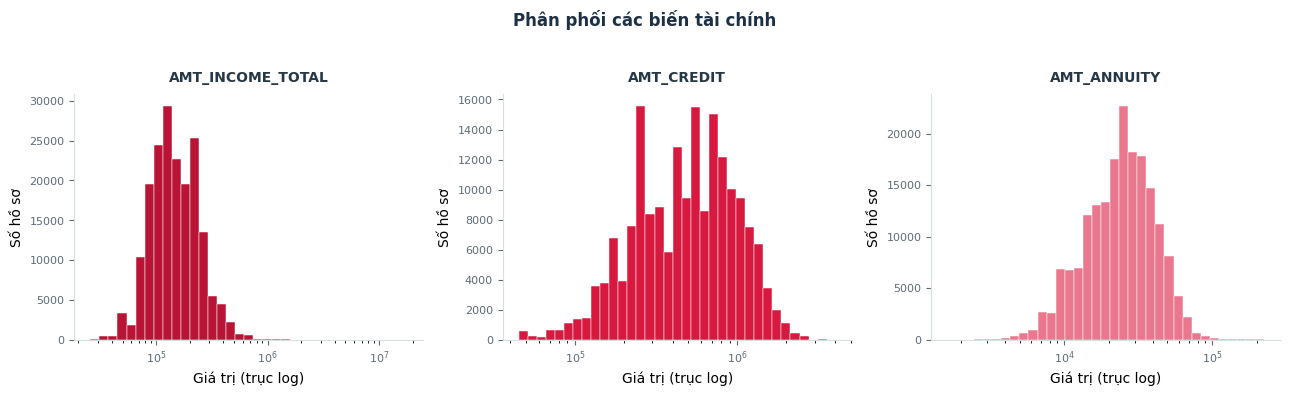

In [17]:
import numpy as np
financial_columns = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']
financial_summary = train[financial_columns].agg(['count', 'median', 'skew']).T
financial_summary['missing_n'] = train[financial_columns].isna().sum()
financial_summary[['count', 'missing_n']] = financial_summary[['count', 'missing_n']].astype('int64')
financial_summary['q1'] = train[financial_columns].quantile(.25)
financial_summary['q3'] = train[financial_columns].quantile(.75)
financial_summary['max'] = train[financial_columns].max()
display(financial_summary[['count', 'missing_n', 'median', 'q1', 'q3', 'max', 'skew']].round(2))

financial_colors = ['#B91435', '#D7193F', '#E9788F']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), facecolor='white')
for column, color, ax in zip(financial_columns, financial_colors, axes):
    values = train[column].dropna()
    ax.hist(values, bins=np.geomspace(values.min(), values.max(), 36), color=color, edgecolor='white', linewidth=.35)
    ax.set_xscale('log')
    ax.set_title(column, fontsize=10, fontweight='semibold', color='#263746', pad=9)
    ax.set_xlabel('Giá trị (trục log)')
    ax.set_ylabel('Số hồ sơ')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
    ax.tick_params(colors='#5E6B75', labelsize=8)
fig.suptitle('Phân phối các biến tài chính', fontsize=12, fontweight='semibold', color='#1D3045', y=1.03)
fig.tight_layout()
plt.show()


<a id="eda-financial-ratios"></a>

### 02.7. Tỷ số khoản vay và khoản trả trên thu nhập

So sánh tỷ lệ `TARGET = 1` giữa các nhóm `Credit / Income` và `Annuity / Income`. Chỉ tính tỷ số khi thu nhập ghi nhận lớn hơn 0; hồ sơ không tính được được ghi riêng trong bảng. Đây là tỷ số mô tả từ các trường hiện có, không đo trực tiếp khả năng chi trả. Dữ liệu chưa xác nhận kỳ thu nhập nên không gọi tỷ số thứ hai là DTI theo tháng.


,ratio,group,n,positive_n,target_rate_pct
0,Credit / Income,Q1,36921,2675,7.25
1,Credit / Income,Q2,36887,3237,8.78
2,Credit / Income,Q3,36910,3292,8.92
3,Credit / Income,Q4,36898,3018,8.18
4,Credit / Income,Q5,36890,2673,7.25
5,Annuity / Income,Q1,36906,2646,7.17
6,Annuity / Income,Q2,36893,2889,7.83
7,Annuity / Income,Q3,36900,3041,8.24
8,Annuity / Income,Q4,36911,3173,8.60
9,Annuity / Income,Q5,36888,3146,8.53


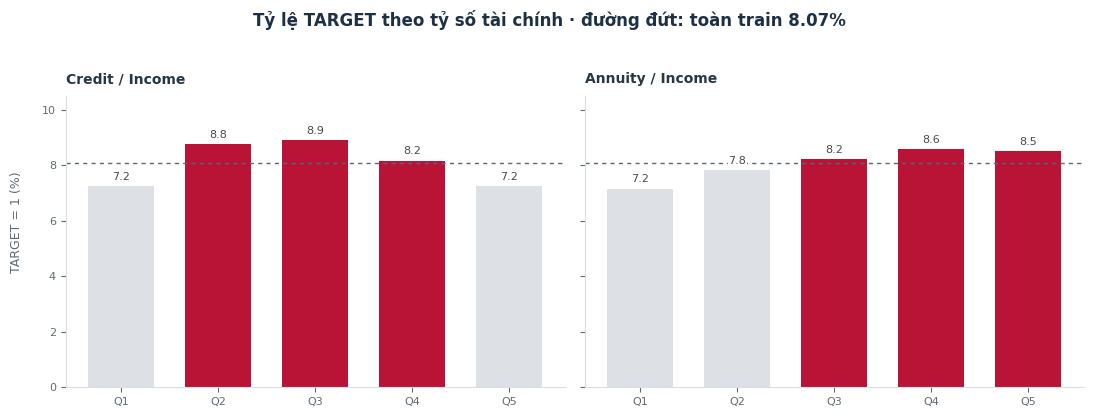

In [18]:
income = train['AMT_INCOME_TOTAL'].where(train['AMT_INCOME_TOTAL'] > 0)
financial_ratio_view = pd.DataFrame(index=train.index)
financial_ratio_view['Credit / Income'] = train['AMT_CREDIT'] / income
financial_ratio_view['Annuity / Income'] = train['AMT_ANNUITY'] / income
financial_ratio_rows = []
for column in financial_ratio_view:
    values = financial_ratio_view[column]
    groups = pd.qcut(values, q=5, labels=False, duplicates='drop')
    grouped = train.groupby(groups, observed=True)['TARGET'].agg(n='size', positive_n='sum')
    grouped['target_rate_pct'] = grouped['positive_n'] / grouped['n'] * 100
    grouped['group'] = [f'Q{int(index) + 1}' for index in grouped.index]
    missing = values.isna()
    if missing.any():
        missing_target = train.loc[missing, 'TARGET']
        grouped.loc[-1, ['n', 'positive_n', 'target_rate_pct', 'group']] = [
            len(missing_target), missing_target.sum(), missing_target.mean() * 100, 'Missing / income \u2264 0'
        ]
    grouped['ratio'] = column
    financial_ratio_rows.append(grouped.reset_index(drop=True))
financial_ratio_target = pd.concat(financial_ratio_rows, ignore_index=True)
financial_ratio_target[['n', 'positive_n']] = financial_ratio_target[['n', 'positive_n']].astype('int64')
display(financial_ratio_target[['ratio', 'group', 'n', 'positive_n', 'target_rate_pct']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor='white')
axis_max = financial_ratio_target.loc[
    ~financial_ratio_target['group'].str.startswith('Missing'), 'target_rate_pct'
].max() * 1.18
for column, ax in zip(financial_ratio_view, axes):
    grouped = financial_ratio_target.loc[
        (financial_ratio_target['ratio'] == column)
        & ~financial_ratio_target['group'].str.startswith('Missing')
    ].copy()
    grouped['_order'] = grouped['group'].map(lambda value: int(value[1:]))
    grouped = grouped.sort_values('_order')
    rates = grouped['target_rate_pct'].to_numpy()
    colors = ['#B91435' if value > default_rate else '#DDE1E5' for value in rates]
    bars = ax.bar(grouped['group'], rates, color=colors, width=.68)
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8, color='#4A4A4A', bbox=dict(facecolor='white', edgecolor='none', pad=.5))
    ax.axhline(default_rate, color='#596875', linestyle=(0, (3, 3)), linewidth=1, zorder=1)
    ax.set_ylim(0, axis_max)
    ax.set_title(column, loc='left', fontsize=10, fontweight='semibold', color='#263746', pad=9)
    ax.set_ylabel('')
    ax.tick_params(axis='x', labelsize=8, colors='#5E6B75')
    ax.tick_params(axis='y', labelsize=8, colors='#5E6B75')
    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#D9DEE3')
fig.supylabel('TARGET = 1 (%)', x=.01, fontsize=9, color='#5E6B75')
fig.suptitle(f'T\u1ef7 l\u1ec7 TARGET theo t\u1ef7 s\u1ed1 t\u00e0i ch\u00ednh \u00b7 \u0111\u01b0\u1eddng \u0111\u1ee9t: to\u00e0n train {default_rate:.2f}%',
             fontsize=12, fontweight='semibold', color='#1D3045', y=1.03)
fig.tight_layout()
plt.show()


### Kết luận mục 02

- Tỷ lệ `TARGET = 1` thay đổi theo một số đặc điểm hồ sơ và lịch sử. `Credit / Income` không tăng đều theo phân vị; `Annuity / Income` tăng từ Q1 đến Q4 rồi gần như giữ nguyên ở Q5.
- Nhóm có dấu hiệu quá hạn được ghi nhận ở bureau/POS có tỷ lệ `TARGET = 1` cao hơn nhóm chưa ghi nhận dấu hiệu. Kết quả cần đọc cùng quy mô và độ bao phủ lịch sử.
- Đây là các mối liên hệ mô tả trên train. Chúng gợi ý nội dung cần xem xét ở bước tạo đặc trưng, nhưng không chứng minh quan hệ nhân quả hay sức dự báo ngoài mẫu.


<a id="part-3"></a>

## 03. Phạm vi lịch sử dùng trong phân tích

Bảng dưới đây cho biết quy mô dòng lịch sử bureau và POS thuộc train, số dòng đủ điều kiện theo quy tắc EDA và số hồ sơ có lịch sử ở mỗi nguồn. Các con số đặt kết quả ở mục 02 vào đúng phạm vi quan sát.

In [19]:
display(history_results['eda_scope'])

,source,train_rows,usable_rows,unverified_rows,train_applications_with_history
0,bureau,879858,879778,80,158165
1,pos_cash_balance,5125192,5125192,0,173672


### Kết luận mục 03

- Bureau có **879.858 dòng** lịch sử thuộc train; **879.778 dòng** đủ điều kiện theo quy tắc EDA và **158.165 hồ sơ** có lịch sử bureau.
- POS có **5.125.192 dòng** thuộc train; **173.672 hồ sơ** có lịch sử POS.

Độ bao phủ khác nhau giữa hai nguồn cần được tính đến khi so sánh tỷ lệ TARGET theo nhóm.


<a id="part-4"></a>

## 04. Kết luận EDA

EDA nhận diện các mẫu hình cần xem xét trong chuẩn bị dữ liệu và xây dựng đặc trưng; các phát hiện không tự xác nhận khả năng dự báo của mô hình.

- Tỷ lệ `TARGET = 1` thay đổi theo điểm `EXT_SOURCE`, tuổi, thâm niên, loại khách hàng, lịch sử bureau/POS và các tỷ số tài chính. Một số quan hệ không đơn điệu, nên không tóm tắt chúng bằng một ngưỡng duy nhất.
- Nhóm có dấu hiệu quá hạn được ghi nhận có tỷ lệ `TARGET = 1` cao hơn ở một số nguồn. Mức bao phủ và dữ liệu chưa xác minh cần được giữ trong diễn giải; thiếu lịch sử không đồng nghĩa lịch sử tốt.
- Các kết quả chỉ mô tả tập train. Notebook 04 sẽ chốt cách tạo và xử lý đặc trưng; giá trị dự báo được đánh giá bằng validation/CV ở các notebook mô hình.